In [12]:
import sys
import torch

import numpy as np
from eszd import ESZD
from eszd.directions import RandomCoords

import matplotlib.pyplot as plt

sys.path.append("../")
from synthetic_utils import *


In [13]:
def run_experiment(optimizer, T = 100, reps = 5):
    f0 = optimizer.target(optimizer.x).item()
    results = [[f0] for _ in range(reps)]
    for r in range(reps):
        for k in range(T):
            x = optimizer.step()
            results[r].append(optimizer.target(x).item())
    return np.mean(results, axis=0), np.std(results, axis=0)


def plot_result(labels, results):
    fig, ax = plt.subplots(1, 1, figsize=(10, 7))
    for (lab, ris) in zip(labels, results):
        mu, std = ris
        ax.plot(range(len(mu)), mu, '-', label=lab)
        ax.fill_between(range(len(mu)), mu - std, mu + std, alpha=0.6)
    ax.set_xlabel("$k$")
    ax.set_ylabel("$f(x_k)$")    

## Deterministic

In [14]:
d = 10
fun_1 = Sphere(d)

In [15]:
l = 5
dtype = torch.float64
device = 'cpu'

P1 = RandomCoords(d = d, l = l, dtype=dtype, device=device)
P2 = RandomCoords(d = d, l = l, dtype=dtype, device=device)

print(P1().shape)

x0 = torch.ones((1, d), dtype=dtype, device=device)

alpha = lambda k : 0.5
h = lambda k : 1e-5

# SINGLE POINT DOESN T WORK => F explodes

two_point = ESZD(fun_1, x0.clone(), P = P1, alpha = alpha, h = h, single_point=False) 
single_point = ESZD(fun_1, x0.clone(), P = P2, alpha = alpha, h = h, single_point=True) 



torch.Size([5, 10])


In [16]:
labels = ['$\ell + 1$ estimator', '$\ell$ estimator']
#def run_experiment(optimizer, T = 100, reps = 5):
#ris_2point = run_experiment(two_point, T = 100, reps = 5)
ris_singlepoint = run_experiment(single_point, T = 100, reps = 5)

results = [ris_2point]#, ris_singlepoint]

tensor([      0.0000,       0.0000, 1000002.0000, 1000002.0000,       0.0000,
              0.0000, 1000002.0000,       0.0000, 1000002.0000, 1000002.0000],
       dtype=torch.float64)
tensor([0.0000e+00, 1.2500e+17, 0.0000e+00, 0.0000e+00, 1.2500e+17, 1.2500e+17,
        0.0000e+00, 1.2500e+17, 0.0000e+00, 1.2500e+17], dtype=torch.float64)
tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.9531e+39,
        1.9531e+39, 1.9531e+39, 1.9531e+39, 1.9531e+39], dtype=torch.float64)
tensor([4.7684e+83, 0.0000e+00, 4.7684e+83, 0.0000e+00, 4.7684e+83, 0.0000e+00,
        4.7684e+83, 0.0000e+00, 4.7684e+83, 0.0000e+00], dtype=torch.float64)
tensor([ 0.0000e+00, 2.8422e+172,  0.0000e+00,  0.0000e+00, 2.8422e+172,
        2.8422e+172, 2.8422e+172, 2.8422e+172,  0.0000e+00,  0.0000e+00],
       dtype=torch.float64)
tensor([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan], dtype=torch.float64)
tensor([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan], dtype=torch.float64)
tensor

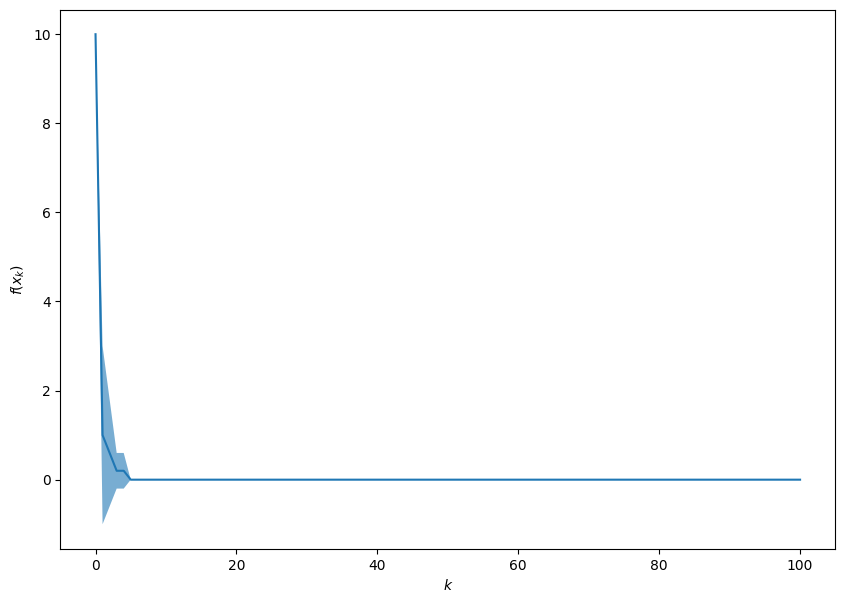

In [17]:
plot_result(labels, results)